# AI Usage Acknowledgment

Generative AI was used to assist in generating Python code for data preprocessing, machine learning model implementation, ensemble and hybrid model
development, evaluation, visualizations, and Streamlit dashboard development.

AI assistance was also used for debugging, troubleshooting and explaining the implementation.

The generated code was executed and tested as part of this assignment. The reported evaluation metrics were obtained from experiments conducted using the selected Sri Lankan dataset.

---



# Climate-Based Flood Risk Classification in Sri Lanka Using Ensemble Learning and Hybrid Machine Learning Models

**224056E - Gamage G.G.P.T.**
## Introduction
This project compares ensemble learning methods for classifying
modeled flood risk using daily climatic observations from
25 Sri Lankan districts between 2015 and 2024.
## Objectives
1. Explore climate and modeled risk patterns.
2. Implement Random Forest and Extra Trees (bagging).
3. Compare XGBoost, LightGBM and CatBoost (boosting).
4. Develop a Logistic Regression stacking ensemble.
5. Compare RF, ANN and RF + ANN soft voting.
6. Use the same train/test split and metrics for all models.
7. Develop an interactive Streamlit dashboard.
## Problem type and target
Binary classification: 0 = Normal Risk, 1 = Elevated Risk.

In [1]:
%pip install -q xgboost lightgbm catboost plotly joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    StackingClassifier, VotingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
from google.colab import files
uploaded = files.upload()

Saving sri_lanka_flood_risk_modeled.csv to sri_lanka_flood_risk_modeled.csv


In [4]:
df = pd.read_csv("sri_lanka_flood_risk_modeled.csv")
display(df.head())

,date,precipitation_sum,rain_sum,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,temperature_2m_max,wind_speed_10m_max,district,latitude,longitude,province,climatic_zone,rain_24h,rain_48h,rain_72h,soil_saturation_index,year,flood_risk_score,flood_category
0,2015-01-01,1.6,1.6,0.375,0.378,29.1,8.2,Ampara,7.2912,81.6724,Eastern,Dry,1.6,1.6,1.6,0.3762,2015,0.2,Low Risk (Normal)
1,2015-01-02,1.3,1.3,0.372,0.373,28.9,7.9,Ampara,7.2912,81.6724,Eastern,Dry,1.3,2.9,2.9,0.3724,2015,0.3,Low Risk (Normal)
2,2015-01-03,0.0,0.0,0.361,0.368,29.4,11.4,Ampara,7.2912,81.6724,Eastern,Dry,0.0,1.3,2.9,0.3638,2015,0.3,Low Risk (Normal)
3,2015-01-04,0.2,0.2,0.349,0.360,29.1,13.9,Ampara,7.2912,81.6724,Eastern,Dry,0.2,0.2,1.5,0.3534,2015,0.1,Low Risk (Normal)
4,2015-01-05,3.3,3.3,0.349,0.353,27.8,16.5,Ampara,7.2912,81.6724,Eastern,Dry,3.3,3.5,3.5,0.3506,2015,0.3,Low Risk (Normal)


In [5]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.info()
display(df.describe())

Shape: (91325, 19)
Columns: ['date', 'precipitation_sum', 'rain_sum', 'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean', 'temperature_2m_max', 'wind_speed_10m_max', 'district', 'latitude', 'longitude', 'province', 'climatic_zone', 'rain_24h', 'rain_48h', 'rain_72h', 'soil_saturation_index', 'year', 'flood_risk_score', 'flood_category']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91325 entries, 0 to 91324
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   date                          91325 non-null  object 
 1   precipitation_sum             91325 non-null  float64
 2   rain_sum                      91325 non-null  float64
 3   soil_moisture_0_to_7cm_mean   91325 non-null  float64
 4   soil_moisture_7_to_28cm_mean  91325 non-null  float64
 5   temperature_2m_max            91325 non-null  float64
 6   wind_speed_10m_max            91325 non-null  float64
 7   distr

,precipitation_sum,rain_sum,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,temperature_2m_max,wind_speed_10m_max,latitude,longitude,rain_24h,rain_48h,rain_72h,soil_saturation_index,year,flood_risk_score
count,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000
mean,5.546671,5.546671,0.332286,0.327313,29.900777,17.156757,7.588212,80.587948,5.546671,11.089380,16.628645,0.330297,2019.500411,4.417119
std,10.224598,10.224598,0.126538,0.120991,3.253310,6.948491,1.033023,0.533065,10.224598,17.677075,24.253368,0.122669,2.872678,10.690699
min,0.000000,0.000000,0.011000,0.017000,14.700000,2.500000,5.954900,79.839400,0.000000,0.000000,0.000000,0.034400,2015.000000,0.000000
25%,0.200000,0.200000,0.233000,0.223000,28.400000,12.100000,6.927100,80.221000,0.200000,0.900000,1.800000,0.230000,2017.000000,0.200000
50%,1.800000,1.800000,0.350000,0.334000,29.800000,16.200000,7.291200,80.498200,1.800000,4.600000,7.800000,0.343200,2020.000000,0.700000
75%,6.700000,6.700000,0.443000,0.430000,31.700000,21.000000,8.311400,81.018800,6.700000,14.600000,22.500000,0.435200,2022.000000,1.900000
max,321.800000,321.800000,0.518000,0.518000,40.400000,76.000000,9.661500,81.674700,321.800000,481.500000,544.100000,0.518000,2024.000000,99.300000


## Dataset description
The CSV contains 91,325 daily observations from 25 districts
of Sri Lanka from 1 January 2015 to 31 December 2024.
It contains rainfall, soil moisture, temperature, wind and
geographical variables.


In [6]:
print(df.isna().sum())
print("Missing total:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("District-date duplicates:",
      df.duplicated(["district", "date"]).sum())

date                            0
precipitation_sum               0
rain_sum                        0
soil_moisture_0_to_7cm_mean     0
soil_moisture_7_to_28cm_mean    0
temperature_2m_max              0
wind_speed_10m_max              0
district                        0
latitude                        0
longitude                       0
province                        0
climatic_zone                   0
rain_24h                        0
rain_48h                        0
rain_72h                        0
soil_saturation_index           0
year                            0
flood_risk_score                0
flood_category                  0
dtype: int64
Missing total: 0
Duplicates: 0
District-date duplicates: 0


### Data Quality Interpretation

No missing values or duplicate records were identified
in the dataset. Therefore, missing value imputation
was not required.

The absence of duplicate district-date combinations
indicates that each daily district observation is unique.

In [7]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df = df.sort_values(["date", "district"]).reset_index(drop=True)
print(df["date"].min(), df["date"].max())
print("Districts:", df["district"].nunique())

2015-01-01 00:00:00 2024-12-31 00:00:00
Districts: 25


### Date Processing Interpretation

The date variable was converted into datetime format,
and the month and year were extracted.

The month represents seasonal climatic patterns,
while the year is used to establish a chronological
training and testing split.

In [8]:
display(df["flood_category"].value_counts())
df["flood_risk"] = (
    df["flood_category"] != "Low Risk (Normal)"
).astype(int)
df["risk_label"] = df["flood_risk"].map({
    0: "Normal Risk", 1: "Elevated Risk"
})
display(df["risk_label"].value_counts())
display(df["risk_label"].value_counts(normalize=True) * 100)

,count
flood_category,
Low Risk (Normal),84693
Advisory (Waterlogging),6458
High Warning (Inundation),128
Critical Emergency (Catastrophic Overflow),46


,count
risk_label,
Normal Risk,84693
Elevated Risk,6632


,proportion
risk_label,
Normal Risk,92.738024
Elevated Risk,7.261976


### Target Variable Interpretation

The original four flood risk categories were converted
into two classes: Normal Risk (0) and Elevated Risk (1).

The three non-normal categories were combined because
the high-warning and critical-emergency categories
contained very few observations.

The transformed dataset contains 84,693 normal-risk
observations and 6,632 elevated-risk observations.

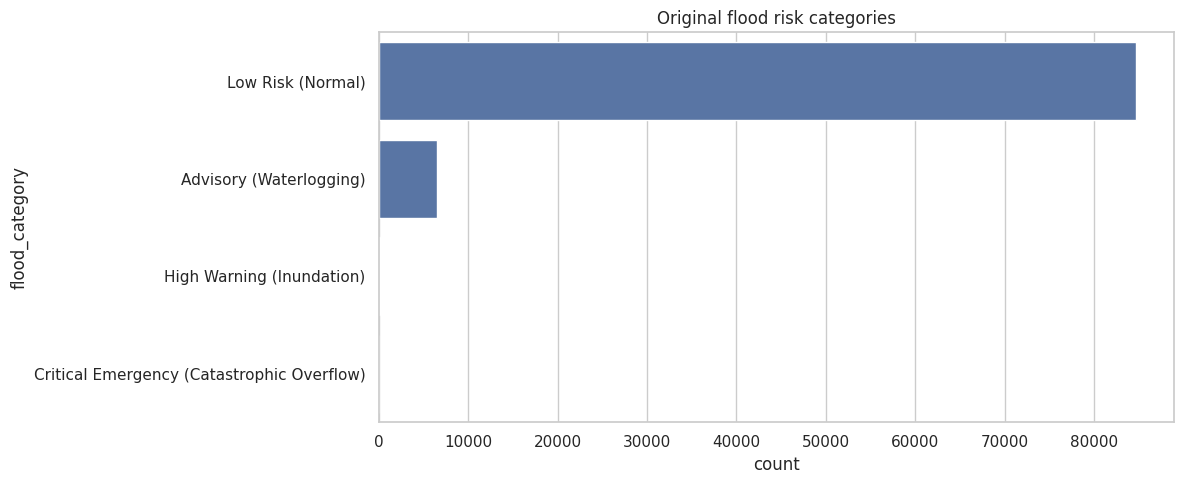

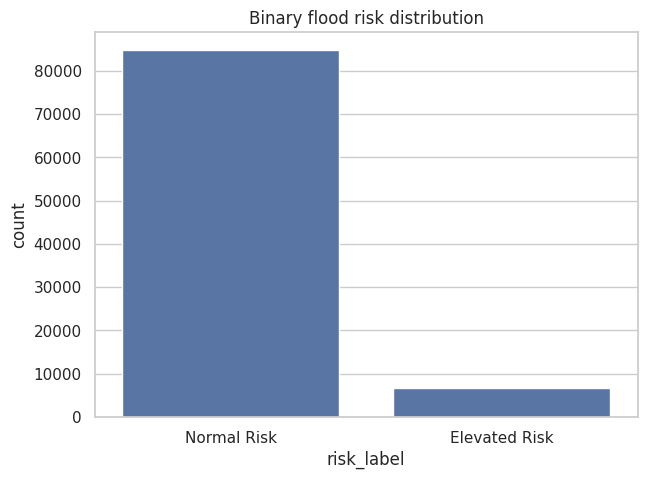

In [9]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="flood_category",
              order=df["flood_category"].value_counts().index)
plt.title("Original flood risk categories")
plt.tight_layout()
plt.show()
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="risk_label")
plt.title("Binary flood risk distribution")
plt.show()

### Class Distribution Interpretation

The dataset is highly imbalanced, with approximately
92.74% normal-risk observations and only 7.26%
elevated-risk observations.

A model could achieve high accuracy by predicting
the majority class without identifying elevated-risk
observations.

Therefore, F1-score, precision and recall are important
evaluation metrics.

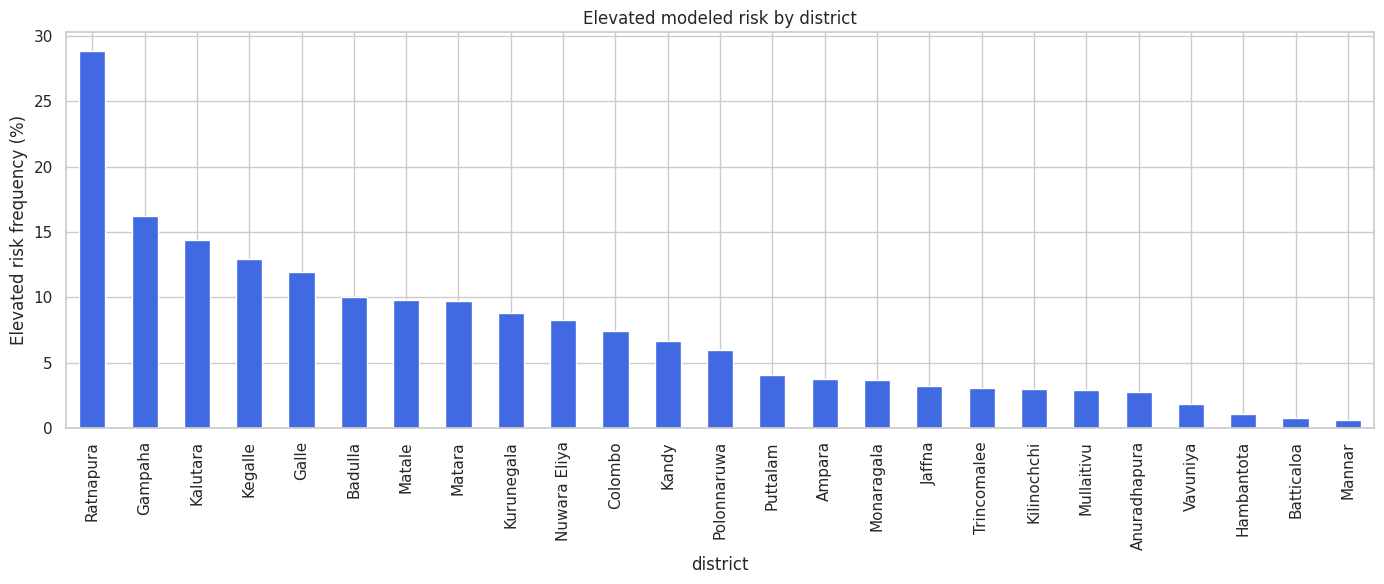

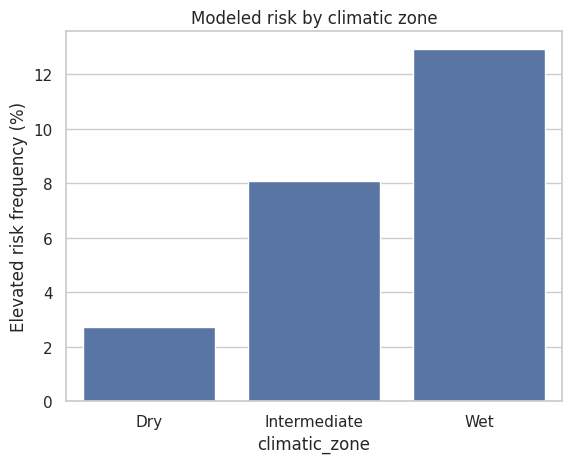

In [10]:
district_risk = (
    df.groupby("district")["flood_risk"].mean()
      .mul(100).sort_values(ascending=False)
)
district_risk.plot(kind="bar", figsize=(14, 6),
                   color="royalblue")
plt.title("Elevated modeled risk by district")
plt.ylabel("Elevated risk frequency (%)")
plt.tight_layout()
plt.show()
zone_risk = (
    df.groupby("climatic_zone")["flood_risk"].mean()
      .mul(100).reset_index()
)
sns.barplot(data=zone_risk, x="climatic_zone", y="flood_risk")
plt.ylabel("Elevated risk frequency (%)")
plt.title("Modeled risk by climatic zone")
plt.show()

### District-Level Risk Interpretation

The frequency of elevated modeled flood risk varies
across Sri Lankan districts.

Ratnapura records the highest proportion of elevated-risk
observations, at approximately 29%.

This variation suggests that regional climatic conditions
and geographical location are relevant to modeled flood
risk classification.

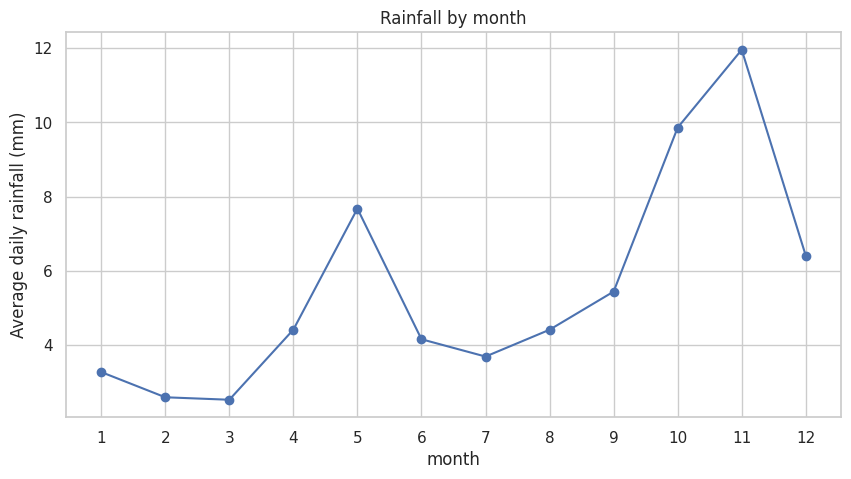

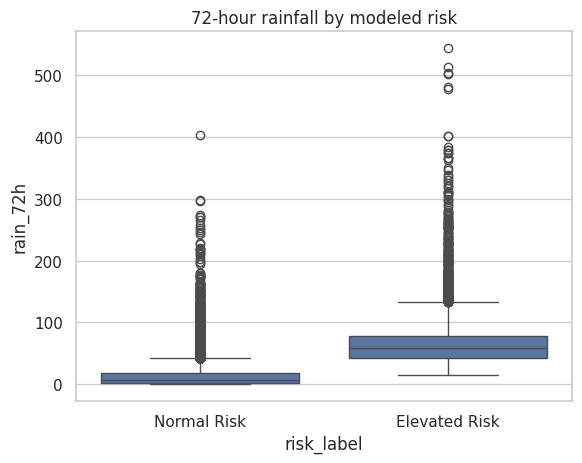

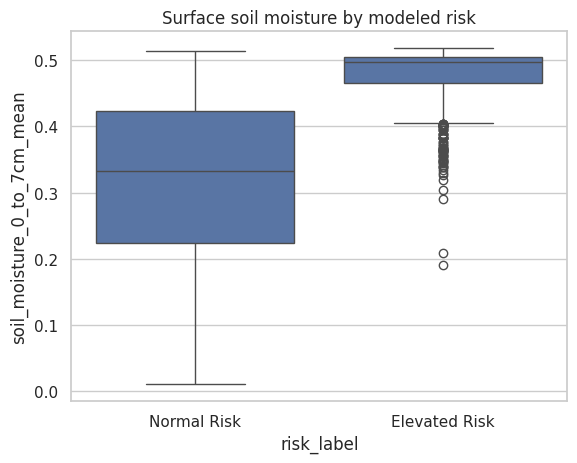

In [11]:
monthly_rainfall = df.groupby("month")["rain_24h"].mean()
monthly_rainfall.plot(marker="o", figsize=(10, 5))
plt.xticks(range(1, 13))
plt.ylabel("Average daily rainfall (mm)")
plt.title("Rainfall by month")
plt.show()
sns.boxplot(data=df, x="risk_label", y="rain_72h")
plt.title("72-hour rainfall by modeled risk")
plt.show()
sns.boxplot(data=df, x="risk_label",
            y="soil_moisture_0_to_7cm_mean")
plt.title("Surface soil moisture by modeled risk")
plt.show()

### Monthly Rainfall Interpretation

The monthly rainfall patterns demonstrate seasonal
variation throughout the year.

Differences in rainfall across months reflect the
seasonal climatic characteristics of Sri Lanka.

Including the month as an input feature allows the
models to learn relationships between seasonality
and modeled flood risk.

### Climatic Feature Interpretation

The boxplots allow rainfall and soil moisture distributions
to be compared between normal-risk and elevated-risk
observations.

These variables are relevant because accumulated rainfall
and soil moisture are associated with modeled flood risk.

The models can use combinations of these climatic variables
to distinguish between the two target classes.

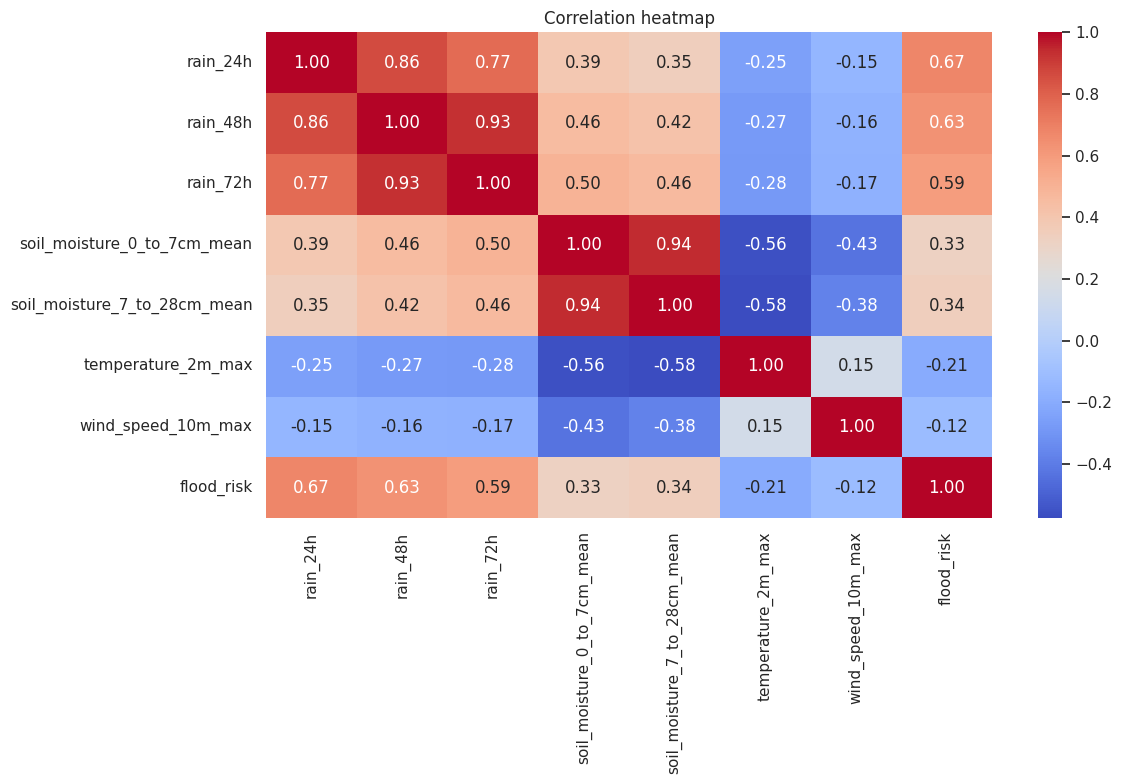

In [12]:
correlation_columns = [
    "rain_24h", "rain_48h", "rain_72h",
    "soil_moisture_0_to_7cm_mean",
    "soil_moisture_7_to_28cm_mean",
    "temperature_2m_max", "wind_speed_10m_max", "flood_risk"
]
plt.figure(figsize=(12, 8))
sns.heatmap(df[correlation_columns].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

### Correlation Analysis Interpretation

The correlation heatmap illustrates relationships between
numerical climatic variables and the target variable.

The 24-hour, 48-hour and 72-hour rainfall variables
are related because they represent accumulated rainfall
over overlapping periods.

Ensemble tree models can capture nonlinear relationships
and interactions that may not be fully represented
by linear correlation coefficients.

Correlation does not establish causation.

In [13]:
features = [
    "district", "climatic_zone",
    "rain_24h", "rain_48h", "rain_72h",
    "soil_moisture_0_to_7cm_mean",
    "soil_moisture_7_to_28cm_mean",
    "temperature_2m_max", "wind_speed_10m_max", "month"
]
target = "flood_risk"
X = df[features]
y = df[target]
print(X.shape, y.shape)
print("Duplicate rain columns:",
      (df["rain_sum"] == df["rain_24h"]).all(),
      (df["precipitation_sum"] == df["rain_24h"]).all())

(91325, 10) (91325,)
Duplicate rain columns: True True


## Feature Selection

Ten input features were selected for flood risk classification.

The target variable is flood_risk, which represents Normal Risk
(0) and Elevated Risk (1).

The rain_sum and precipitation_sum variables were excluded
because they contain identical values to rain_24h.

The flood_risk_score variable was excluded to prevent target leakage.

The resulting feature matrix contains 91,325 observations and
10 input features.

In [14]:
train = df[df["year"] <= 2022].copy()
test = df[df["year"] >= 2023].copy()
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print("Training:", len(X_train))
print("Testing:", len(X_test))
print(y_train.value_counts())
print(y_test.value_counts())

Training: 73050
Testing: 18275
flood_risk
0    68001
1     5049
Name: count, dtype: int64
flood_risk
0    16692
1     1583
Name: count, dtype: int64


## Train-Test Split

The dataset was divided using an approximately 80:20
chronological train-test split.

Observations from 2015 to 2022 were used for training,
while observations from 2023 to 2024 were used for testing.

The training set contains 73,050 observations, and the
testing set contains 18,275 observations.

A chronological split was selected to prevent future
observations from influencing model training.


In [15]:
categorical_features = ["district", "climatic_zone"]
numerical_features = [
    col for col in features if col not in categorical_features
]
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numerical_features),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore", sparse_output=False
    ), categorical_features)
])
def make_pipeline(model):
    return Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
     ])

### Preprocessing Interpretation

Standardization was applied to numerical variables,
which is particularly important for ANN training.

Preprocessing was incorporated into pipelines and
fitted using training data to prevent data leakage.

In [16]:
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Preprocessing pipeline created successfully.")

Categorical features: ['district', 'climatic_zone']
Numerical features: ['rain_24h', 'rain_48h', 'rain_72h', 'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean', 'temperature_2m_max', 'wind_speed_10m_max', 'month']
Preprocessing pipeline created successfully.


In [17]:
rf = RandomForestClassifier(
    n_estimators=100, class_weight="balanced",
    random_state=42, n_jobs=2
)
extra_trees = ExtraTreesClassifier(
    n_estimators=100, class_weight="balanced",
    random_state=42, n_jobs=2
)

## Bagging Models

Random Forest and Extra Trees were selected as the bagging
ensemble models.

Both models use 100 decision trees. Balanced class weights
were applied to address the class imbalance in the dataset.

Random Forest is the main model used in this study.
Extra Trees introduces additional randomness during tree
construction to reduce variance.

In [18]:
xgb = XGBClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.1,
    random_state=42, eval_metric="logloss", n_jobs=2
)
lgbm = LGBMClassifier(
    n_estimators=100, learning_rate=0.1, num_leaves=31,
    random_state=42, verbosity=-1, n_jobs=2
)
catboost = CatBoostClassifier(
    iterations=100, depth=6, learning_rate=0.1,
    random_seed=42, verbose=False, thread_count=2,
    allow_writing_files=False
)

### Boosting Model Interpretation

XGBoost, LightGBM and CatBoost were selected to
investigate gradient boosting performance.

Unlike bagging, boosting develops trees sequentially,
with each new tree improving the existing ensemble.

Boosting can capture complex nonlinear relationships
between rainfall, soil moisture and other climatic variables.

In [19]:
ann = MLPClassifier(
    hidden_layer_sizes=(64, 32), activation="relu",
    solver="adam", max_iter=200, early_stopping=True,
    random_state=42
)

### ANN Interpretation

A Multi-Layer Perceptron was implemented as an
artificial neural network.

The ANN learns nonlinear relationships through
interconnected hidden layers.

It also provides a standalone reference for evaluating
the effectiveness of the RF + ANN hybrid model.

In [20]:
group_cv = GroupKFold(n_splits=3)
cv_splits = list(group_cv.split(
    X_train, y_train, groups=train["year"]
))
stacking = StackingClassifier(
    estimators=[
        ("rf", make_pipeline(rf)),
        ("et", make_pipeline(extra_trees)),
        ("xgb", make_pipeline(xgb)),
        ("lgbm", make_pipeline(lgbm)),
        ("cat", make_pipeline(catboost))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba",
    cv=cv_splits, n_jobs=1
)

### Stacking Model Interpretation

The stacking classifier combines Random Forest,
Extra Trees, XGBoost, LightGBM and CatBoost.

Logistic Regression was selected as the meta-model
to learn how to combine predictions from the base models.

Stacking may improve performance by using the
complementary strengths of multiple algorithms.
However, it introduces additional computational complexity.

In [21]:
hybrid = VotingClassifier(
    estimators=[
        ("rf", make_pipeline(rf)),
        ("ann", make_pipeline(ann))
    ],
    voting="soft", weights=[1, 1], n_jobs=1
)

### Hybrid Model Interpretation

The hybrid model combines Random Forest and ANN
using soft voting.

The predicted class probabilities from both models
are averaged to produce the final classification.

This experiment investigates whether combining
tree-based learning and neural network learning
improves predictive performance.

In [22]:
models = {
    "Baseline": make_pipeline(
        DummyClassifier(strategy="most_frequent")),
    "Random Forest": make_pipeline(rf),
    "Extra Trees": make_pipeline(extra_trees),
    "XGBoost": make_pipeline(xgb),
    "LightGBM": make_pipeline(lgbm),
    "CatBoost": make_pipeline(catboost),
    "ANN": make_pipeline(ann),
    "Stacking": stacking,
    "RF + ANN Hybrid": hybrid
}

In [23]:
results = []
trained_models = {}
predictions_df = pd.DataFrame({
    "date": test["date"].to_numpy(),
    "district": test["district"].to_numpy(),
    "actual": y_test.to_numpy()
})
for name, model in models.items():
    print("Training", name)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred,
                                     zero_division=0),
        "Recall": recall_score(y_test, y_pred,
                               zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(
            y_test, y_prob),
        "Training Time": training_time
    })
    predictions_df[f"{name}_prediction"] = y_pred
    predictions_df[f"{name}_probability"] = y_prob
    trained_models[name] = model
    print(f"Completed in {training_time:.2f} seconds")
results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)
display(results_df.round(4))
best_model = results_df.iloc[0]
print("Highest test F1:", best_model["Model"])

Training Baseline
Completed in 0.19 seconds
Training Random Forest
Completed in 8.51 seconds
Training Extra Trees
Completed in 5.29 seconds
Training XGBoost
Completed in 1.06 seconds
Training LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Completed in 0.74 seconds
Training CatBoost
Completed in 4.34 seconds
Training ANN
Completed in 9.48 seconds
Training Stacking


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Completed in 44.91 seconds
Training RF + ANN Hybrid
Completed in 16.21 seconds


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision,Training Time
0,CatBoost,0.9972,0.9799,0.9874,0.9836,0.9999,0.9991,4.3444
1,Stacking,0.9972,0.9817,0.9855,0.9836,0.9999,0.9990,44.9085
2,XGBoost,0.9971,0.9793,0.9874,0.9833,0.9999,0.9990,1.0587
3,Random Forest,0.9969,0.9835,0.9804,0.9820,0.9999,0.9989,8.5111
4,LightGBM,0.9963,0.9761,0.9810,0.9786,0.9999,0.9989,0.7377
5,RF + ANN Hybrid,0.9962,0.9684,0.9880,0.9781,0.9999,0.9989,16.2065
6,ANN,0.9940,0.9499,0.9823,0.9658,0.9997,0.9963,9.4763
7,Extra Trees,0.9912,0.9804,0.9166,0.9474,0.9991,0.9909,5.2936
8,Baseline,0.9134,0.0000,0.0000,0.0000,0.5000,0.0866,0.1854


Highest test F1: CatBoost


## Model Training and Evaluation Results

All nine models were trained and evaluated using the same
chronological training and testing datasets.

CatBoost achieved the highest F1-score of 0.9836 and an
accuracy of 99.72%, making it the best-performing model
in this experiment.

The stacking classifier achieved nearly identical predictive
performance but required significantly more training time.

Among the gradient boosting models, LightGBM recorded
the shortest training time.

The RF + ANN hybrid achieved an F1-score of 0.9781,
outperforming the standalone ANN but not Random Forest.
However, it achieved the highest recall of 98.80%.

The high performance should be interpreted in the context
of modeled flood risk labels rather than independently
confirmed flood events.

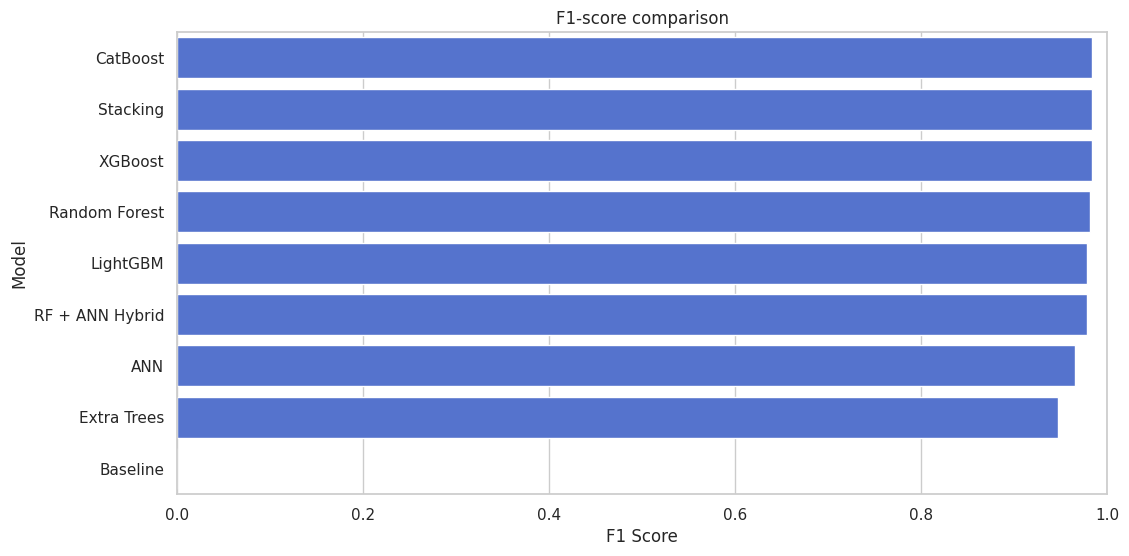

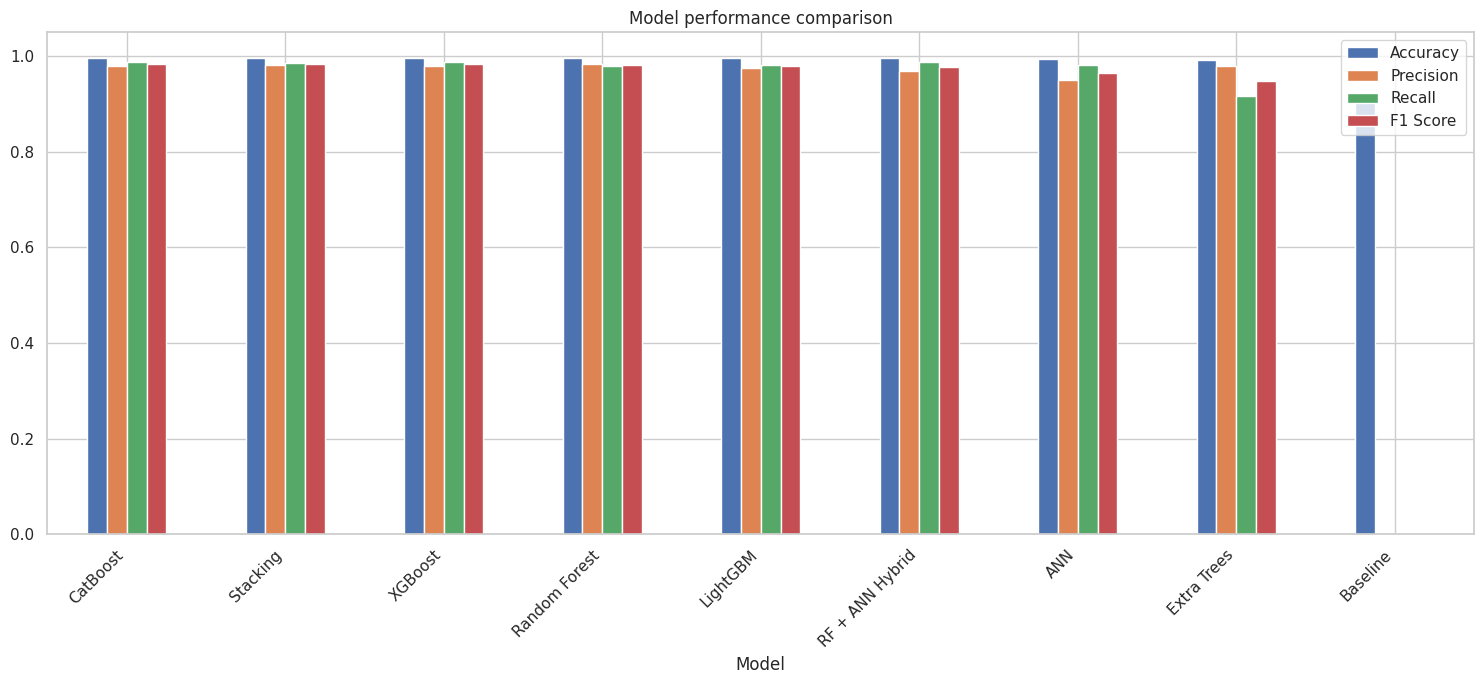

In [24]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results_df, x="F1 Score", y="Model",
            color="royalblue")
plt.title("F1-score comparison")
plt.xlim(0, 1)
plt.show()
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(15, 7))
plt.ylim(0, 1.05)
plt.title("Model performance comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Model Performance Comparison

Most ensemble models achieved strong classification
performance on the held-out testing dataset.

CatBoost, Stacking and XGBoost produced the highest
F1-scores, followed closely by Random Forest.

The results suggest that ensemble learning is effective
for capturing relationships within this structured
climatic dataset.

However, the small differences between the top-performing
models should not be interpreted as evidence of a
statistically significant performance advantage.

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision,Training Time
0,CatBoost,0.9972,0.9799,0.9874,0.9836,0.9999,0.9991,4.3444
2,XGBoost,0.9971,0.9793,0.9874,0.9833,0.9999,0.9990,1.0587
3,Random Forest,0.9969,0.9835,0.9804,0.9820,0.9999,0.9989,8.5111
4,LightGBM,0.9963,0.9761,0.9810,0.9786,0.9999,0.9989,0.7377


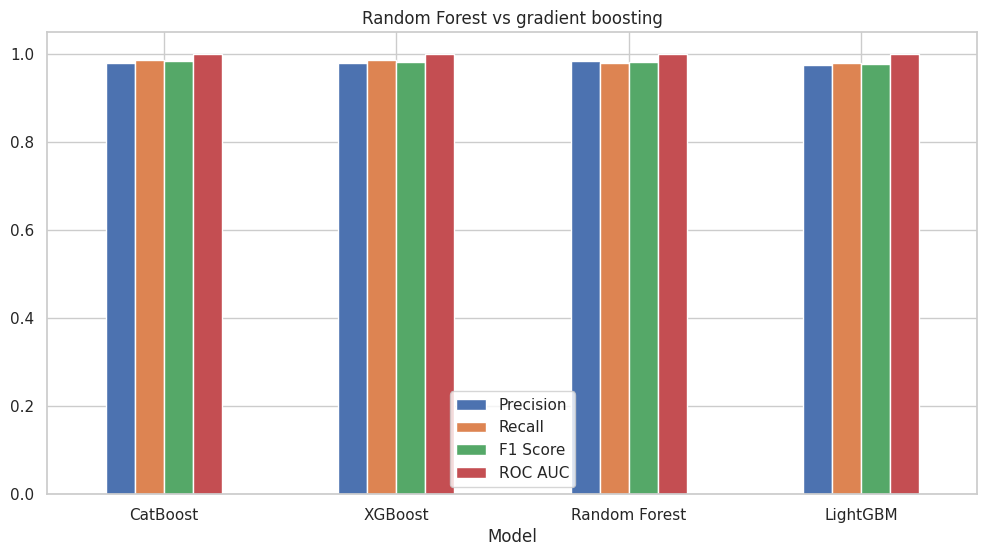

RF/boosting comparison winner: CatBoost


In [26]:
rf_boosting_results = results_df[
    results_df["Model"].isin([
        "Random Forest", "XGBoost", "LightGBM", "CatBoost"
    ])
]
display(rf_boosting_results.round(4))
rf_boosting_results.set_index("Model")[
    ["Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(kind="bar", figsize=(12, 6))
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.title("Random Forest vs gradient boosting")
plt.show()
comparison_winner = rf_boosting_results.loc[
    rf_boosting_results["F1 Score"].idxmax()
]
print("RF/boosting comparison winner:", comparison_winner["Model"])

### Random Forest vs Gradient Boosting Interpretation

CatBoost achieved the highest F1-score of 0.9836,
followed by XGBoost at 0.9833, Random Forest at 0.9820
and LightGBM at 0.9786.

CatBoost's strong performance may be attributed to
its sequential learning process and ability to capture
nonlinear interactions between climatic variables.

Random Forest achieved the highest precision among
these four models, at 98.35%, while requiring less
complex hyperparameter tuning in general.

LightGBM achieved the shortest training time.

The findings indicate that gradient boosting can
provide strong predictive performance, although
Random Forest remains a competitive alternative.

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision,Training Time
3,Random Forest,0.9969,0.9835,0.9804,0.9820,0.9999,0.9989,8.5111
5,RF + ANN Hybrid,0.9962,0.9684,0.9880,0.9781,0.9999,0.9989,16.2065
6,ANN,0.9940,0.9499,0.9823,0.9658,0.9997,0.9963,9.4763


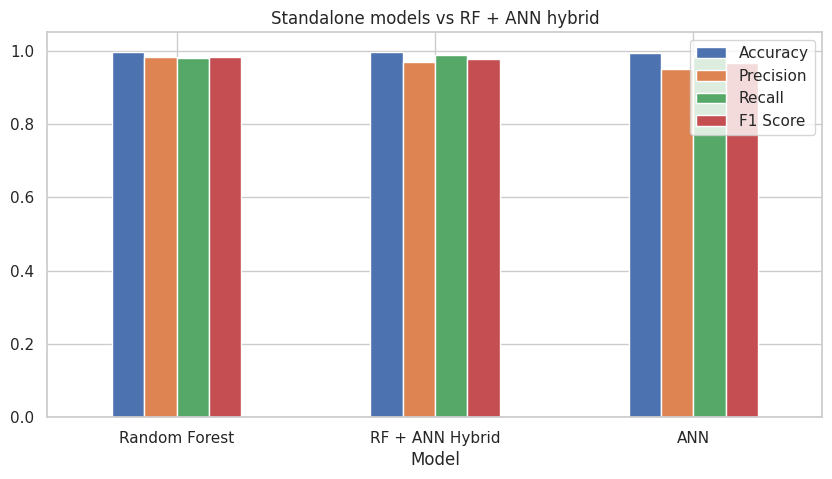

In [27]:
hybrid_results = results_df[
    results_df["Model"].isin([
        "Random Forest", "ANN", "RF + ANN Hybrid"
    ])
]
display(hybrid_results.round(4))
hybrid_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))
plt.title("Standalone models vs RF + ANN hybrid")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()

### Hybrid Model Performance Interpretation

The RF + ANN hybrid achieved an F1-score of 0.9781,
compared with 0.9820 for Random Forest and 0.9658
for the standalone ANN.

Therefore, the hybrid improved upon the ANN but
did not outperform Random Forest in F1-score.

However, the hybrid achieved the highest recall
of 98.80% among all evaluated models.

This indicates that the hybrid identifies a greater
proportion of elevated-risk observations, although
its lower precision reduces its overall F1-score.

Combining models does not necessarily guarantee
better performance across every evaluation metric.

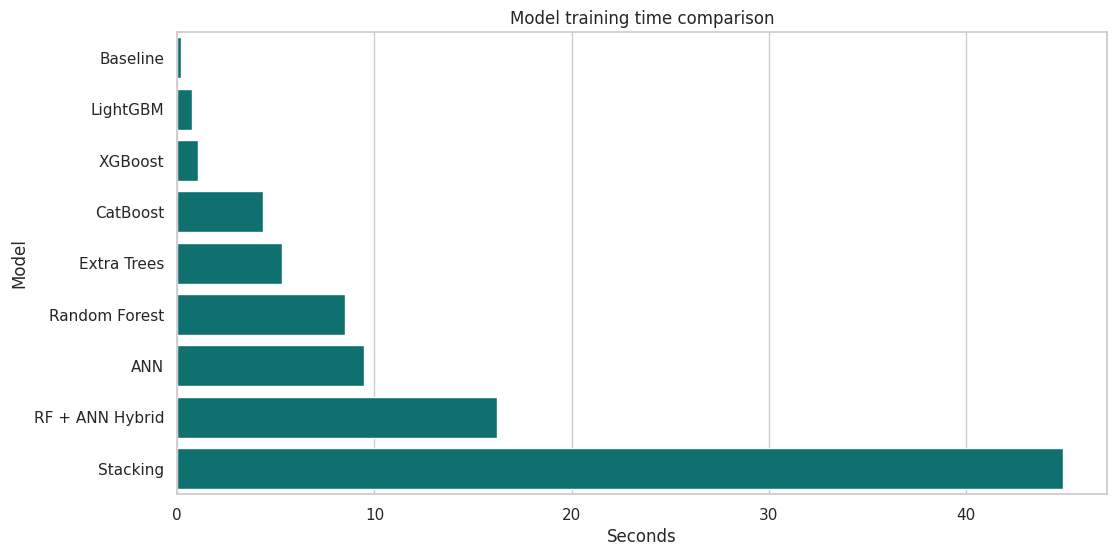

In [28]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results_df.sort_values("Training Time"),
            x="Training Time", y="Model", color="teal")
plt.title("Model training time comparison")
plt.xlabel("Seconds")
plt.show()

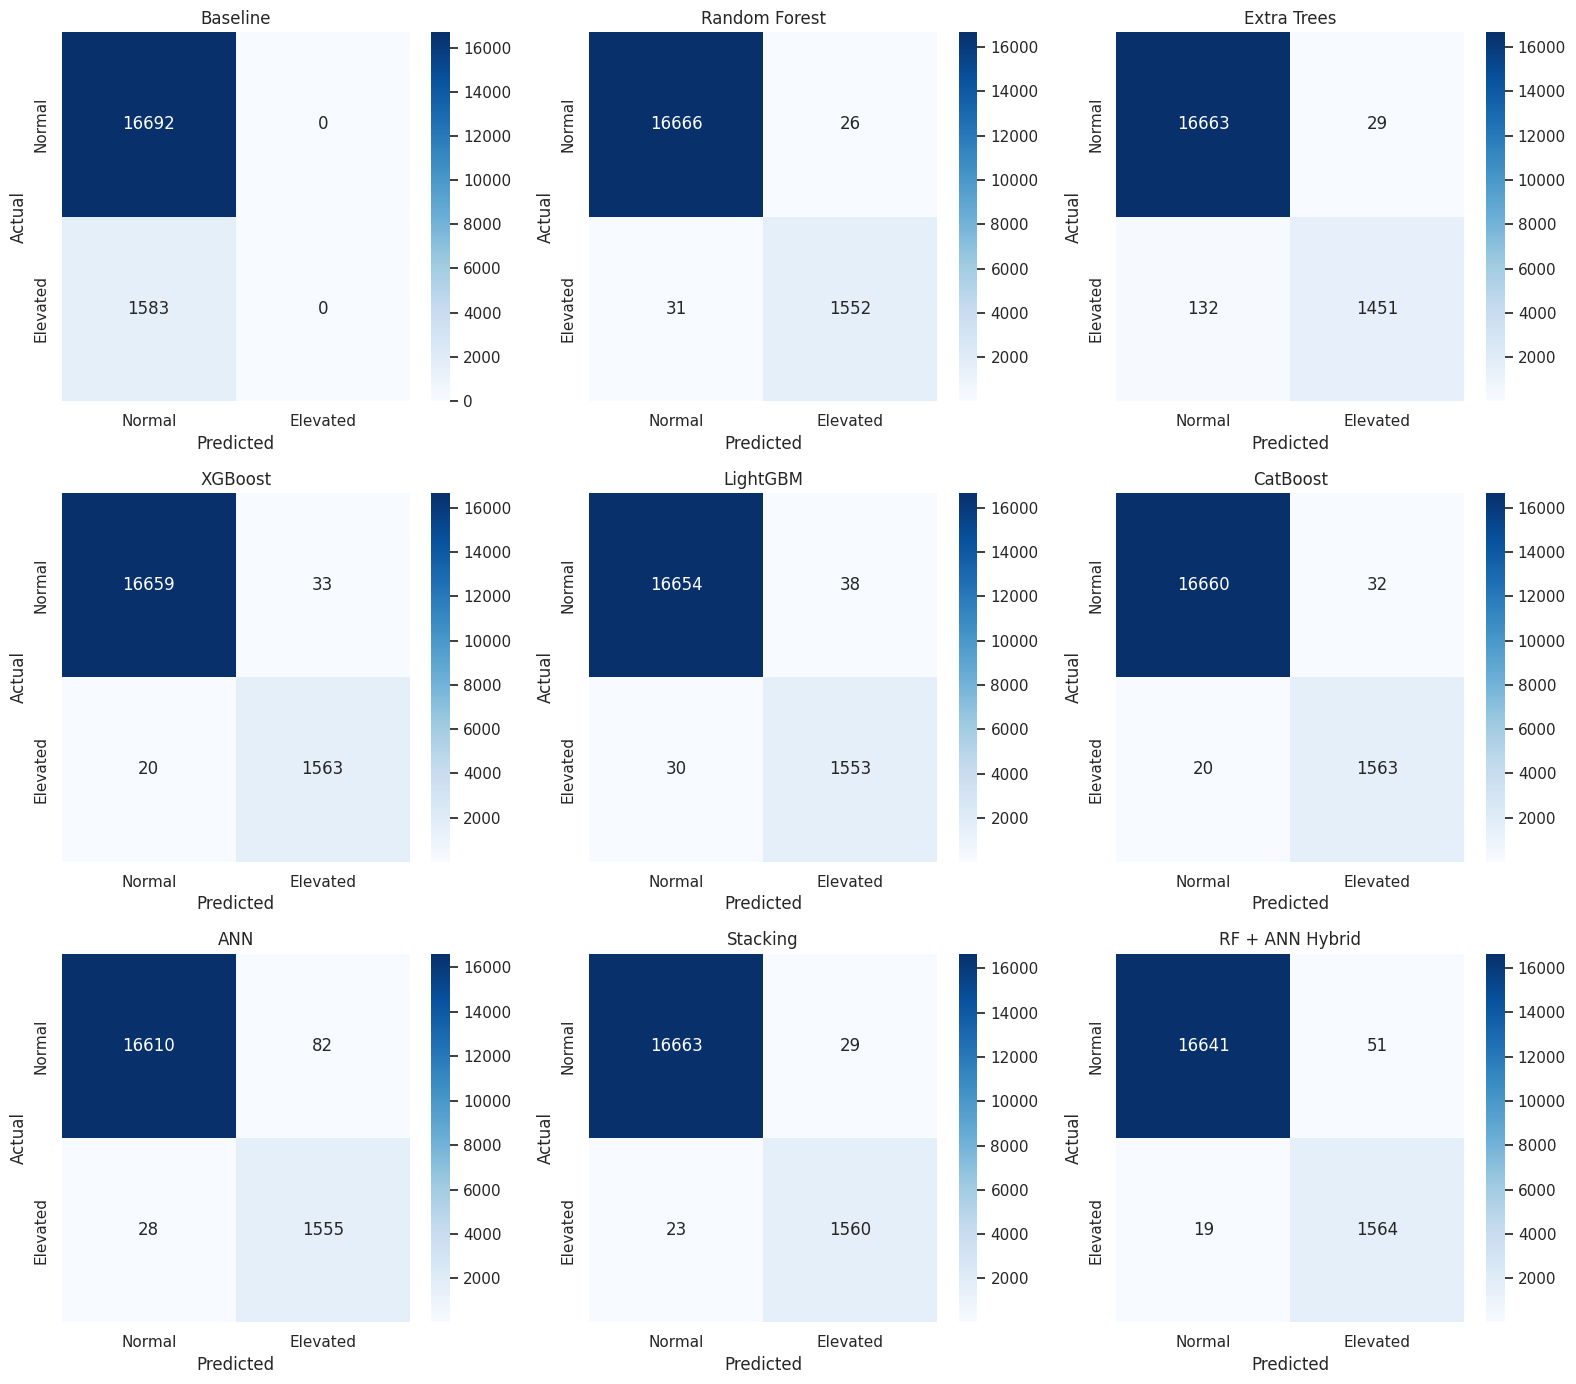

In [29]:
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for ax, name in zip(axes.flatten(), trained_models):
    cm = confusion_matrix(
        y_test, predictions_df[f"{name}_prediction"],
        labels=[0, 1]
    )
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Elevated"],
                yticklabels=["Normal", "Elevated"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### Confusion Matrix Interpretation

CatBoost correctly classified 16,660 normal-risk
observations and 1,563 elevated-risk observations.

It produced 32 false positives and 20 false negatives.

False negatives are particularly important because
they represent elevated-risk observations incorrectly
classified as normal.

The relatively low number of false negatives indicates
strong sensitivity to elevated modeled risk.

However, these results evaluate modeled labels,
not independently verified flood events.

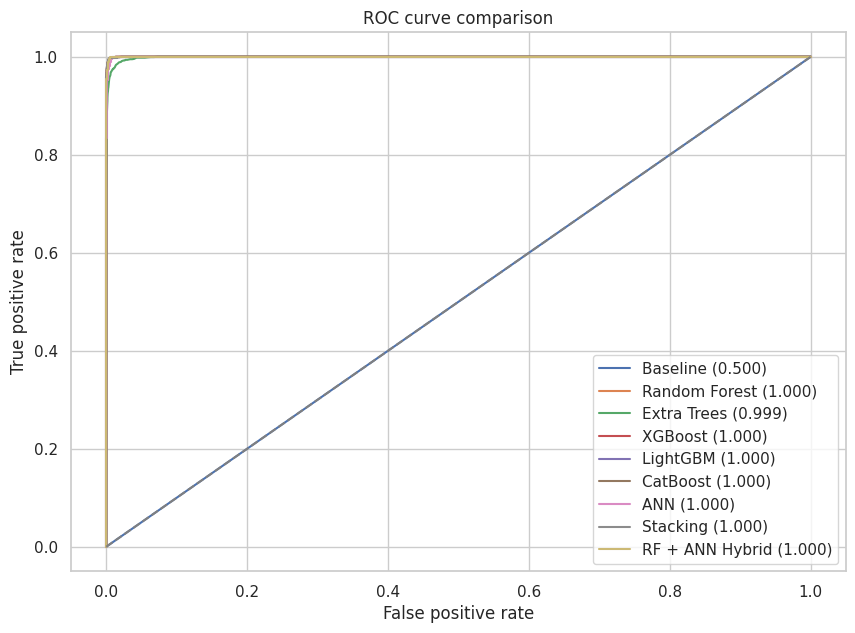

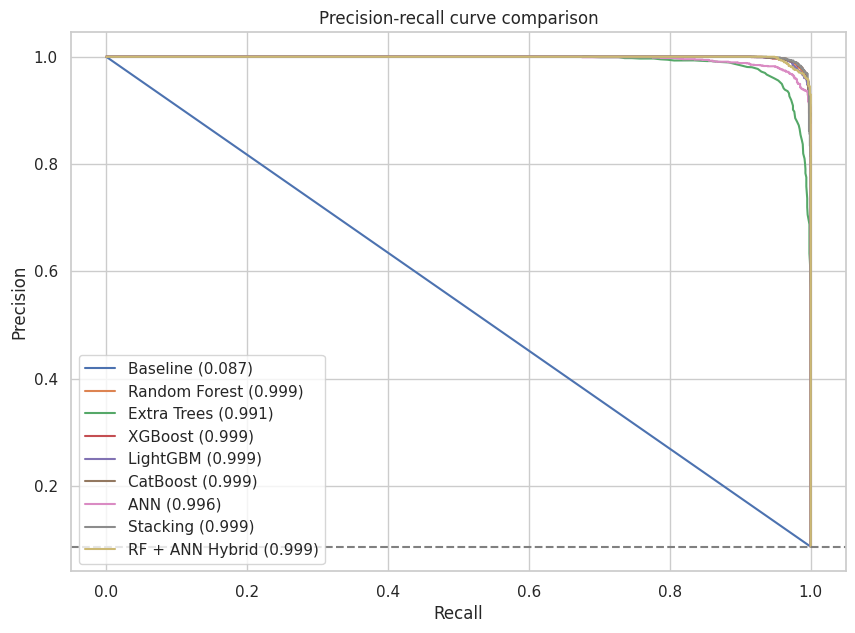

In [30]:
plt.figure(figsize=(10, 7))
for name in trained_models:
    prob = predictions_df[f"{name}_probability"]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} ({auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve comparison")
plt.legend()
plt.show()
plt.figure(figsize=(10, 7))
for name in trained_models:
    prob = predictions_df[f"{name}_probability"]
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f"{name} ({ap:.3f})")
plt.axhline(y_test.mean(), linestyle="--", color="gray")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve comparison")
plt.legend()
plt.show()

,Feature,Importance
0,numeric__rain_24h,0.439701
1,numeric__rain_48h,0.220752
2,numeric__rain_72h,0.120520
3,numeric__soil_moisture_0_to_7cm_mean,0.104089
4,numeric__soil_moisture_7_to_28cm_mean,0.047565
5,numeric__temperature_2m_max,0.023458
33,categorical__climatic_zone_Dry,0.016180
35,categorical__climatic_zone_Wet,0.007057
7,numeric__month,0.006688
6,numeric__wind_speed_10m_max,0.004337


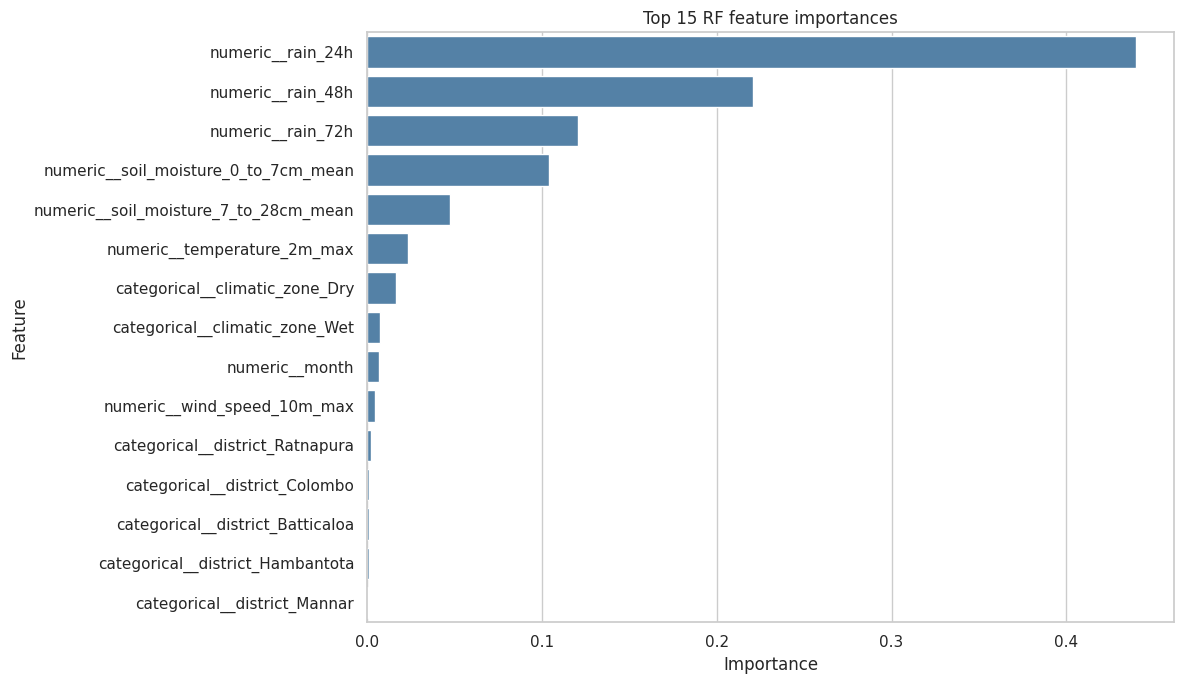

In [31]:
rf_pipeline = trained_models["Random Forest"]
feature_names = (
    rf_pipeline.named_steps["preprocessing"].get_feature_names_out()
)
importance_values = (
    rf_pipeline.named_steps["model"].feature_importances_
)
importance_df = pd.DataFrame({
    "Feature": feature_names, "Importance": importance_values
}).sort_values("Importance", ascending=False)
display(importance_df.head(15))
plt.figure(figsize=(12, 7))
sns.barplot(data=importance_df.head(15),
            x="Importance", y="Feature", color="steelblue")
plt.title("Top 15 RF feature importances")
plt.tight_layout()
plt.show()

In [32]:
winner = results_df.iloc[0]
scores = results_df.set_index("Model")["F1 Score"]
print(f"Best model: {winner['Model']}")
print(f"F1: {winner['F1 Score']:.4f}")
print(f"Accuracy: {winner['Accuracy']:.4f}")
print(f"Precision: {winner['Precision']:.4f}")
print(f"Recall: {winner['Recall']:.4f}")
print("RF/boosting winner:", comparison_winner["Model"])
for name in ["Random Forest", "ANN", "RF + ANN Hybrid"]:
    print(f"{name}: F1 = {scores[name]:.4f}")
if scores["RF + ANN Hybrid"] > max(
    scores["Random Forest"], scores["ANN"]
):
    print("Hybrid outperformed both standalone models.")
else:
    print("Hybrid did not outperform both standalone models.")

Best model: CatBoost
F1: 0.9836
Accuracy: 0.9972
Precision: 0.9799
Recall: 0.9874
RF/boosting winner: CatBoost
Random Forest: F1 = 0.9820
ANN: F1 = 0.9658
RF + ANN Hybrid: F1 = 0.9781
Hybrid did not outperform both standalone models.


## Conclusion

This study evaluated bagging, boosting, stacking and hybrid
machine learning models for flood risk classification across
25 districts of Sri Lanka.

CatBoost was the best-performing model on the held-out test
dataset, achieving an F1-score of 0.9836, accuracy of 99.72%,
precision of 97.99% and recall of 98.74%.

Among Random Forest and the three gradient boosting algorithms,
CatBoost achieved the highest F1-score. Its strong performance
may be attributed to its ability to capture complex nonlinear
relationships between climatic variables. It also achieved a
relatively short training time of 4.34 seconds, compared with
8.51 seconds for Random Forest.

Stacking achieved nearly identical predictive performance
but required considerably more training time.

The RF + ANN hybrid achieved an F1-score of 0.9781, compared
with 0.9820 for Random Forest and 0.9658 for ANN. Therefore,
the hybrid outperformed the standalone ANN but did not
outperform Random Forest. However, it achieved the highest
recall of 98.80% among all evaluated models.

Overall, CatBoost provided the best balance of classification
performance and computational efficiency in this experiment.

In [33]:
from pathlib import Path
import importlib.metadata as metadata
import platform
import shutil
output_dir = Path("Flood_Risk_Project")
output_dir.mkdir(exist_ok=True)
joblib.dump(trained_models,
            output_dir / "trained_models.pkl", compress=3)
df.to_csv(output_dir / "cleaned_flood_data.csv", index=False)
results_df.to_csv(output_dir / "model_results.csv", index=False)
predictions_df.to_csv(output_dir / "model_predictions.csv",
                      index=False)
importance_df.to_csv(output_dir / "feature_importance.csv",
                     index=False)
joblib.dump({"features": features,
             "best_model": best_model["Model"]},
            output_dir / "project_config.pkl")
shutil.copy("sri_lanka_flood_risk_modeled.csv", output_dir)
packages = [
    "pandas", "numpy", "scipy", "scikit-learn",
    "xgboost", "lightgbm", "catboost", "joblib"
]
with open(output_dir / "requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={metadata.version(package)}\n")
    f.write("streamlit\nplotly\n")
print("Python version:", platform.python_version())

Python version: 3.13.18


In [34]:
for file in output_dir.iterdir():
    print(file.name)

requirements.txt
project_config.pkl
sri_lanka_flood_risk_modeled.csv
trained_models.pkl
cleaned_flood_data.csv
model_results.csv
feature_importance.csv
model_predictions.csv


In [35]:
loaded = joblib.load(output_dir / "trained_models.pkl")
print(loaded["Random Forest"].predict(X_test.head()))
print(list(output_dir.iterdir()))
shutil.make_archive("Flood_Risk_Project", "zip", output_dir)
from google.colab import files
files.download("Flood_Risk_Project.zip")

[0 0 0 0 0]
[PosixPath('Flood_Risk_Project/requirements.txt'), PosixPath('Flood_Risk_Project/project_config.pkl'), PosixPath('Flood_Risk_Project/sri_lanka_flood_risk_modeled.csv'), PosixPath('Flood_Risk_Project/trained_models.pkl'), PosixPath('Flood_Risk_Project/cleaned_flood_data.csv'), PosixPath('Flood_Risk_Project/model_results.csv'), PosixPath('Flood_Risk_Project/feature_importance.csv'), PosixPath('Flood_Risk_Project/model_predictions.csv')]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import xgboost
import sklearn
import numpy
import joblib

print("XGBoost:", xgboost.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Joblib:", joblib.__version__)

XGBoost: 3.4.1
Scikit-learn: 1.6.1
NumPy: 2.4.6
Joblib: 1.6.0


In [4]:
from google.colab import files

uploaded = files.upload()

Saving trained_models.pkl to trained_models.pkl


In [6]:
%pip install -q catboost lightgbm

In [7]:
import joblib

loaded_models = joblib.load("trained_models.pkl")

print(list(loaded_models.keys()))

['Baseline', 'Random Forest', 'Extra Trees', 'XGBoost', 'LightGBM', 'CatBoost', 'ANN', 'Stacking', 'RF + ANN Hybrid']


In [8]:
import joblib
from pathlib import Path

portable_dir = Path("portable_models")
portable_dir.mkdir(exist_ok=True)

models = joblib.load("trained_models.pkl")

# Export standalone XGBoost
xgb_pipeline = models["XGBoost"]

xgb_pipeline.named_steps["model"].save_model(
    str(portable_dir / "xgboost_model.json")
)

xgb_pipeline.steps[-1] = ("model", None)

# Export XGBoost inside the stacking ensemble
stacking_xgb = models["Stacking"].named_estimators_["xgb"]

stacking_xgb.named_steps["model"].save_model(
    str(portable_dir / "stacking_xgboost.json")
)

stacking_xgb.steps[-1] = ("model", None)

# Save remaining models and preprocessing pipelines
joblib.dump(
    models,
    portable_dir / "trained_models_portable.pkl",
    compress=3
)

print("Portable models exported successfully.")

Portable models exported successfully.


In [9]:
import shutil
from google.colab import files

shutil.make_archive(
    "portable_models",
    "zip",
    "portable_models"
)

files.download("portable_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>